In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import numpy as np
from src.config import *
from src.utils import *
from src.experiments import run_experiment, show

seed: 105


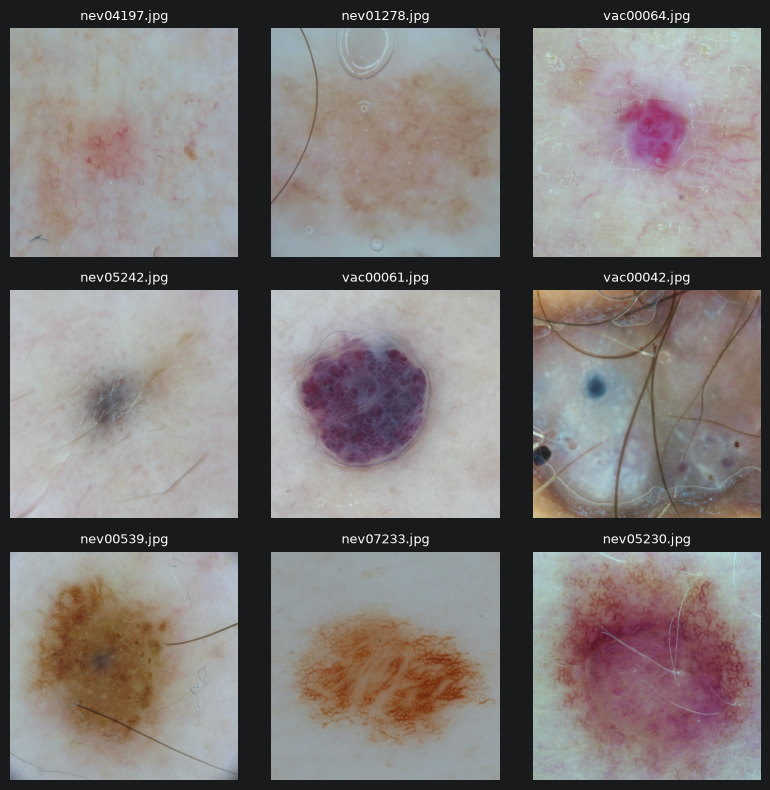

In [2]:
gt_subset = pd.read_csv(BINARY_GT_TRAIN_SUBSET_CSV)
sample = random_sample(gt_subset)
images = [load_preprocessed(r.filename, r.label, BINARY_PREPROC_NOHAIR_TRAIN_DIR) for r in sample.itertuples()]
show_grid(images, [r.filename for r in sample.itertuples()])

In [3]:
train_nh = pd.read_csv(BINARY_FEATURES_NOHAIR_TRAIN_CSV)
train_e0 = pd.read_csv(BINARY_FEATURES_TRAIN_CSV)
assert (train_nh["filename"] == train_e0["filename"]).all()   # same images, same order as E0

feature_cols = [c for c in train_nh.columns if c not in ("filename", "label")]
table_nh, fitted_nh = run_experiment("E4 no hair removal",
                                     train_nh[feature_cols].values, train_nh["label"].values,
                                     only=["SVM (RBF)"])
show(table_nh)

[E4 no hair removal] SVM (RBF): balanced acc = 0.857


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,E4 no hair removal,SVM (RBF),0.858 ± 0.010,0.857 ± 0.010,0.866 ± 0.016,0.848 ± 0.013,0.927 ± 0.008


In [4]:
all_exp = pd.read_csv(RESULTS_DIR / "exp1_feature_selection.csv")
e0 = all_exp[all_exp["experiment"] == "E0 all features"]
e0_svm = e0[e0["model"] == "SVM (RBF)"]

delta = (table_nh.set_index("model")["balanced_accuracy"] - e0.set_index("model")["balanced_accuracy"]).round(3)
print("Change in balanced accuracy (no hair - with hair):\n", delta)

table_nh.to_csv(RESULTS_DIR / "exp2_no_hair.csv", index=False)

show(pd.concat([e0_svm, table_nh], ignore_index=True))

Change in balanced accuracy (no hair - with hair):
 model
CatBoost           NaN
HistGradBoost      NaN
LogReg             NaN
Random Forest      NaN
SVM (RBF)       -0.001
XGBoost            NaN
Name: balanced_accuracy, dtype: float64


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,E0 all features,SVM (RBF),0.858 ± 0.009,0.858 ± 0.009,0.868 ± 0.011,0.848 ± 0.012,0.923 ± 0.010
1,E4 no hair removal,SVM (RBF),0.858 ± 0.010,0.857 ± 0.010,0.866 ± 0.016,0.848 ± 0.013,0.927 ± 0.008
